**Name:** Rachel Sara Mathew  |  **Sec:** G  |  **SRN:** PES2UG24CS390


# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [ ]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = 1920 * 1080 * 3 * 1 / 1024**2          # W x H x C x B (bytes) -> MB

# TODO 2: frames per camera per day at 30 fps
frames_per_day = FPS * 24 * 60 * 60               # f x T

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = frame_mb * 1024**2 * frames_per_day * 400 / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * 3
fleet_tb_small = small_frame_bytes * (10 * 24 * 60 * 60) * 400 / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

A 1080p RGB frame is about 5.93 MB, so 400 cameras at 30 fps for 24 h is roughly 5,866 TB per day uncompressed, versus about 217 TB at 360p/10 fps (only 11.1% of the pixels per frame, a 27x saving). Spatially, the downsample throws away fine detail such as a face or a licence-plate number that was recorded at 1080p; this cannot be recovered by interpolation, which only invents smooth values. Temporally, at 10 fps a fast event (the person starting to run, an object being thrown) can fall between frames, and it is harder to match the same object from one frame to the next (the correspondence problem).


## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

Contrast before: 0.609  ->  after: 1.000


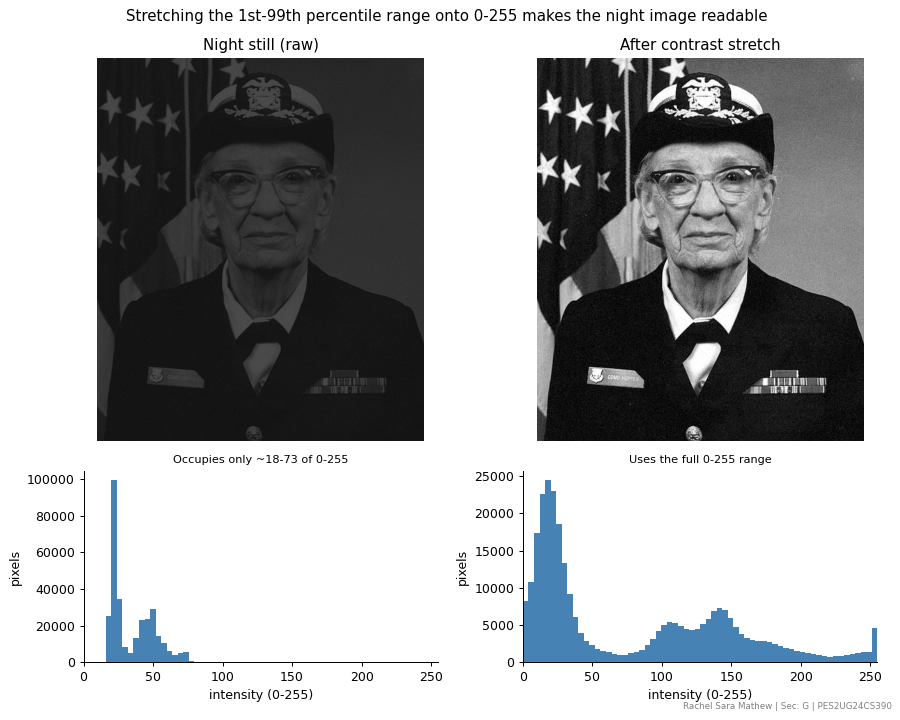

In [ ]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

q1, q99 = np.percentile(stretched, [1, 99])
c_after = michelson(q99, q1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for j, (im, name) in enumerate([(night_still, "Night still (raw)"), (stretched, "After contrast stretch")]):
    axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, j].axis("off"); axes[0, j].set_title(name)
    axes[1, j].hist(im.ravel(), bins=64, range=(0, 255), color="steelblue")
    axes[1, j].set(xlabel="intensity (0-255)", ylabel="pixels", xlim=(0, 255))
axes[1, 0].set_title(f"Occupies only ~{p1:.0f}-{p99:.0f} of 0-255", fontsize=9)
axes[1, 1].set_title("Uses the full 0-255 range", fontsize=9)
fig.suptitle("Stretching the 1st-99th percentile range onto 0-255 makes the night image readable")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The night histogram is a single narrow, low-valued peak (dark, low-contrast and unimodal), crowded into roughly the 20-60 range. Michelson contrast was about 0.61 before and 1.0 after the stretch. Stretching only re-maps the occupied range onto 0-255, so no new information is added; the differences were already in the data but were too close together for the eye to separate. A histogram only counts how many pixels have each value; it throws away where they are, so two completely different pictures can share one histogram and it can never say what is in the image.


## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

standing :   68.7 s ->   78.1 s  (8.6 s in total)
running  :   78.6 s ->   86.0 s  (7.4 s in total)
audio rises above -20 dB at 75.00 s | brightness jump at 100.00 s


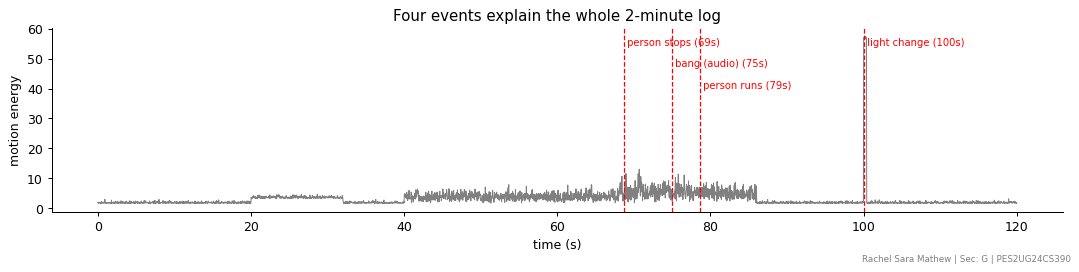

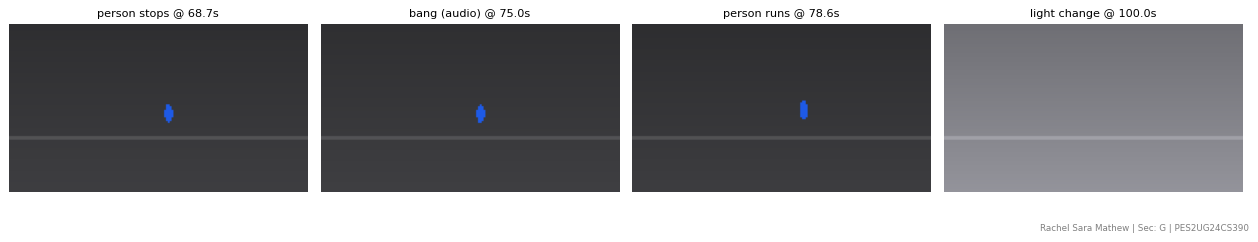

In [ ]:
# TODO 1: person speed (px/s)  -- displacement over a 1-second window (FPS frames)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))      # px per second
t = cctv.time_s.values

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = (speed < 3).values
running = (speed > 25).values
for name, m in [("standing", standing), ("running", running)]:
    print(f"{name:9s}: {t[m].min():6.1f} s -> {t[m].max():6.1f} s  ({m.sum() / FPS:.1f} s in total)")

# TODO 3: event frame indices
audio_event_idx = int(np.argmax(cctv.audio_level_db.values > -20))
lighting_event_idx = int(np.argmax(cctv.mean_brightness.diff().abs().values > 40))
run_start_idx = int(np.argmax(running))
stand_start_idx = int(np.argmax(standing))
print(f"audio rises above -20 dB at {t[audio_event_idx]:.2f} s | brightness jump at {t[lighting_event_idx]:.2f} s")

# TODO 4: annotated motion-energy timeline
events = {"person stops": stand_start_idx, "bang (audio)": audio_event_idx,
          "light change": lighting_event_idx, "person runs": run_start_idx}
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv.motion_energy, lw=0.8, color="gray")
for k, (lab, i) in enumerate(sorted(events.items(), key=lambda kv: kv[1])):
    ax.axvline(t[i], color="red", ls="--", lw=1)
    ax.text(t[i], ax.get_ylim()[1] * (0.95 - 0.12 * (k % 3)), f" {lab} ({t[i]:.0f}s)", color="red", fontsize=8, va="top")
ax.set(xlabel="time (s)", ylabel="motion energy", title="Four events explain the whole 2-minute log")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axs = plt.subplots(1, 4, figsize=(14, 2.8))
for a, (lab, i) in zip(axs, sorted(events.items(), key=lambda kv: kv[1])):
    a.imshow(render_frame(cctv.iloc[i])); a.axis("off"); a.set_title(f"{lab} @ {t[i]:.1f}s", fontsize=9)
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

With one keyframe every 20 s, the sudden light change at 100 s, the 75 s bang and the 79 s start of running could all fall between samples, because events are short and the rest of the log is quiet. I used content-based keyframes: motion vectors give events, events give a timeline and one representative frame each (structure, pattern, change, event, meaning), which is the content-based (event-driven) keyframe selection named on Slide 40.


## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.991, 'MYSTERY (74.5-76.5 s)': 0.879}
Verdict: the 75 s bang is GLASS BREAKING (HF energy fraction 0.88 vs glass 0.99 / gunshot 0.00).


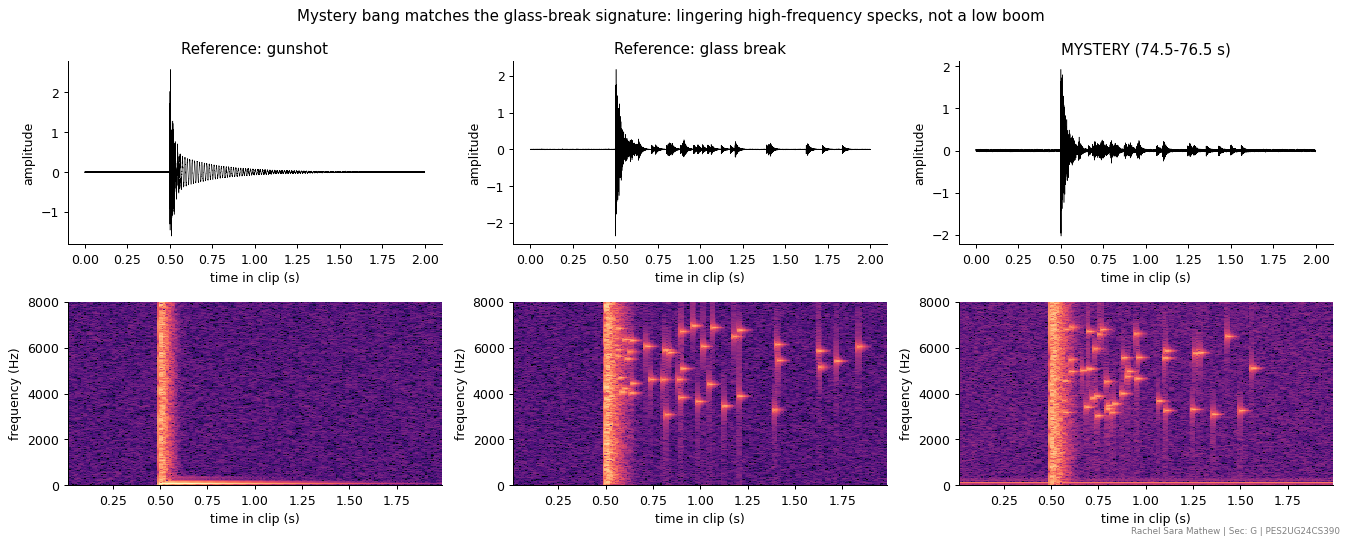

In [ ]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
tt = np.arange(int(2 * FS)) / FS
for j, (name, x) in enumerate(clips.items()):
    axes[0, j].plot(tt, x, lw=0.4, color="k"); axes[0, j].set(title=name, xlabel="time in clip (s)", ylabel="amplitude")
    f, ts, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    axes[1, j].pcolormesh(ts, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-30)
    axes[1, j].set(ylim=(0, 8000), xlabel="time in clip (s)", ylabel="frequency (Hz)")
fig.suptitle("Mystery bang matches the glass-break signature: lingering high-frequency specks, not a low boom")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    seg = x[(tt >= 0.7) & (tt < 1.7)]
    fr, P = signal.periodogram(seg, fs=FS)
    hf_fraction[name] = float(P[fr > 3000].sum() / P.sum())

print({k: round(v, 3) for k, v in hf_fraction.items()})
# TODO 4: verdict
verdict = "GLASS BREAKING" if abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction["Reference: glass break"]) < abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction["Reference: gunshot"]) else "GUNSHOT"
print(f"Verdict: the 75 s bang is {verdict} (HF energy fraction {hf_fraction['MYSTERY (74.5-76.5 s)']:.2f} vs glass {hf_fraction['Reference: glass break']:.2f} / gunshot {hf_fraction['Reference: gunshot']:.2f}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

No. All three waveforms are short loud bursts followed by decay, and a gunshot and a glass break look alike in amplitude-versus-time. The spectrogram adds the three dimensions time (x), frequency (y) and magnitude (colour). The deciding pattern was the scattered high-frequency specks lingering after the impact: the mystery clip has about 88% of its energy above 3 kHz, like the glass reference (99%), while the gunshot has a vertical stripe plus a low horizontal band and almost nothing above 3 kHz (0.3%).


## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

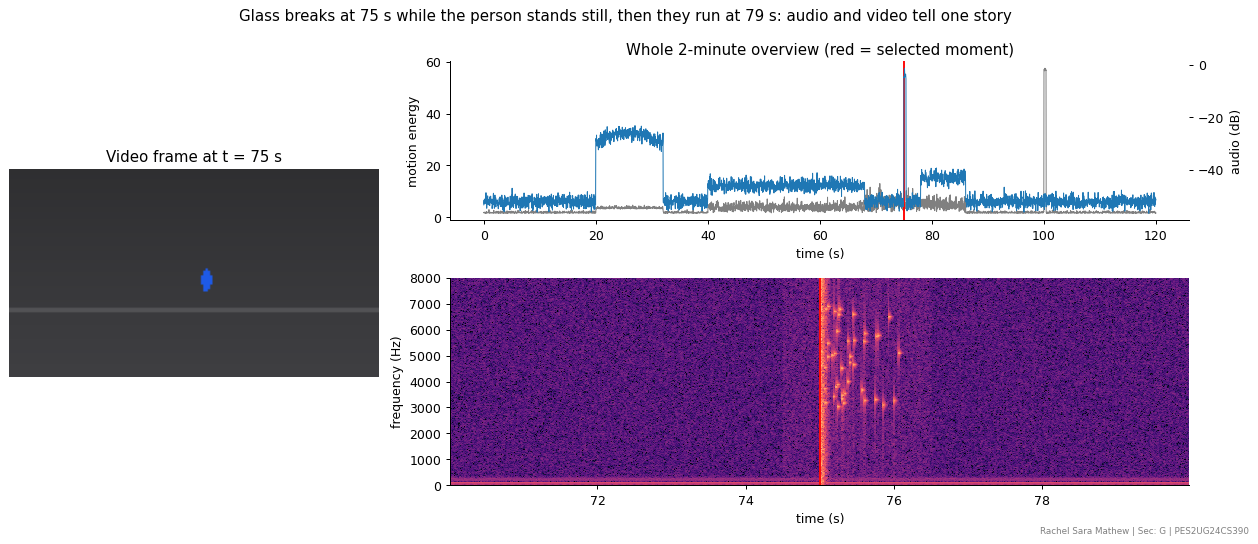

In [ ]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
i_sel = int(round(t_sel * FPS))
ax0 = fig.add_subplot(gs[:, 0]); ax0.imshow(render_frame(cctv.iloc[i_sel])); ax0.axis("off")
ax0.set_title(f"Video frame at t = {t_sel:.0f} s")
ax1 = fig.add_subplot(gs[0, 1])
ax1.plot(cctv.time_s, cctv.motion_energy, color="gray", lw=0.8, label="motion energy")
ax1b = ax1.twinx(); ax1b.plot(cctv.time_s, cctv.audio_level_db, color="tab:blue", lw=0.8, label="audio level (dB)")
ax1.axvline(t_sel, color="red"); ax1.set(xlabel="time (s)", ylabel="motion energy"); ax1b.set_ylabel("audio (dB)")
ax1.set_title("Whole 2-minute overview (red = selected moment)")
ax2 = fig.add_subplot(gs[1, 1])
m10 = (t_audio >= 70) & (t_audio < 80)
f, ts, Sxx = signal.spectrogram(x_audio[m10], fs=FS, nperseg=512, noverlap=384)
ax2.pcolormesh(70 + ts, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-30)
ax2.axvline(t_sel, color="red"); ax2.set(ylim=(0, 8000), xlabel="time (s)", ylabel="frequency (Hz)")
fig.suptitle("Glass breaks at 75 s while the person stands still, then they run at 79 s: audio and video tell one story", fontsize=12)

plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

If the audio were shifted by 2 s, the bang would appear to happen around 77 s (or 73 s) while the video frame at 75 s shows no event, so someone might think the person ran in response to nothing, or that the glass break was caused by something it did not coincide with. The spectrogram panel with the red marker would make the mistake visible: the marker at 75 s would no longer sit on the high-frequency burst.


## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

At 75 s there was a glass break, not a gunshot (about 88% of the energy above 3 kHz, matching the glass reference), while the person stood still from about 69 s; they began running at about 79 s until 86 s, and the lighting changed sharply at 100 s. I would open the briefing with the synchronized one-screen view, because it follows overview first: the timeline shows the events (structure to pattern to change to event) and the frame plus spectrogram give time x frequency x magnitude evidence from two modalities at the same instant. For storage, keep full 1080p only for event windows (e.g. around the 75-86 s activity) and drop to 360p/10 fps otherwise, which cuts the 5,866 TB/day fleet total towards the 217 TB/day floor; the audio track must not be downsampled below the ~16 kHz sampling rate, since the glass-versus-gunshot evidence lives above 3 kHz.
